# Project 2: Active Learning for Scanned Document Classification

**Deliverable 1, HITL WiSe 2026/27.** This notebook investigates whether active learning can reduce the number of labeled pages needed to classify scanned business documents. It builds on our baseline (`Baseline_01.ipynb`): same data, same final model, same metric.

**Question:** If a person can only label a limited number of pages, does choosing them with an acquisition strategy work better than choosing them at random?

## 1. Experimental setup

| Setting | Choice | Reason |
|---|---|---|
| Data | 2,400 OCR pages, 8 classes (RVL-CDIP sample, 300 per class) | same as the baseline |
| Unlabeled pool | 1,924 training pages (labels hidden) | labels are revealed only when a page is selected (simulated oracle) |
| Evaluation | 235 validation pages, macro-F1 | same metric as the baseline; the test set is not used here |
| Model | character n-gram TF-IDF (3–5) + logistic regression | final model of the baseline |
| Initial labeled set | 20 pages per class = 160 (≈8% of the pool) | within the suggested 5–10%; every class is present |
| Batch size / rounds | 40 pages per round, 10 rounds | |
| Annotation budget | 400 additional labels (160 → 560 labeled pages) | about 29% of the pool |
| Repetitions | 5 seeds (different initial sets) | to measure variability |

**Strategies compared (same initial set, budget, model and validation data):**
- **Random sampling:** baseline for comparison.
- **Uncertainty: least confidence:** pages where the model's top probability is lowest. Our baseline showed that wrong predictions have lower confidence (median 0.22 vs 0.43).
- **Diversity: farthest-first:** pages that are different from the labeled set and from each other, to avoid a batch of near-duplicates.
- **Representativeness: relative representativeness:** pages that are typical of the unlabeled pool but under-represented in the labeled set.

**Reference:** the baseline model trained on **all 1,924** labeled pages reached validation macro-F1 **0.726**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity

# Same prepared data as in the baseline (300 pages per class)
data_dir = Path.cwd() / "data" / "prepared" / "rvl_cdip_small_300"
documents = pd.read_csv(data_dir / "dataset.csv").fillna({"ocr_text": ""})

# reset_index: row positions must match the rows of the feature matrix later
train_df = documents[documents["source_split"] == "train"].reset_index(drop=True)
validation_df = documents[documents["source_split"] == "validation"].reset_index(drop=True)
# The test set is not used in this notebook

print(f"Training pool (active-learning candidates): {len(train_df)}")
print(f"Validation set (evaluation): {len(validation_df)}")
display(train_df["label"].value_counts())

Training pool (active-learning candidates): 1924
Validation set (evaluation): 235


label
presentation     244
email            241
news article     241
resume           241
advertisement    240
form             240
invoice          239
letter           238
Name: count, dtype: int64

## 2. Features, initial labeled set and first model

- **Features:** character n-gram TF-IDF with the same settings as the final baseline model. It is fitted once on the OCR text of the training pool. This uses only the text, not the labels, so it does not reveal any hidden labels. The same vectors are used by the classifier and by the diversity and representativeness strategies (cosine similarity).
- **Initial labeled set:** 20 random pages per class (160 pages). All other training pages form the unlabeled pool.
- **Simulated oracle:** labels (`y_train`) are only used for pages that are in the labeled set.

In [2]:
# Character n-gram TF-IDF, same settings as the final baseline model.
# Fitted on the OCR text of the training pool only (no labels are used here).
vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df["ocr_text"])
X_validation = vectorizer.transform(validation_df["ocr_text"])
y_train = train_df["label"].to_numpy()
y_validation = validation_df["label"].to_numpy()

# Experiment settings
N_INITIAL_PER_CLASS = 20   # 8 classes x 20 = 160 initial labels
BATCH_SIZE = 40            # pages labeled per round
N_ROUNDS = 10              # 10 x 40 = 400 additional labels
SEEDS = [42, 43, 44, 45, 46]


def create_initial_set(seed):
    """Initial labeled set: 20 pages per class. All other training pages form the unlabeled pool."""
    labeled = (
        train_df.groupby("label", group_keys=False)
        .sample(n=N_INITIAL_PER_CLASS, random_state=seed)
        .index.to_numpy()
    )
    pool = np.setdiff1d(np.arange(len(train_df)), labeled)
    return labeled, pool


def train_and_evaluate(labeled):
    """Train on the labeled pages only and evaluate on the validation set."""
    model = LogisticRegression(class_weight="balanced", max_iter=1_000, random_state=42)
    model.fit(X_train[labeled], y_train[labeled])   # oracle: only labeled pages reveal their label
    predictions = model.predict(X_validation)
    accuracy = accuracy_score(y_validation, predictions)
    macro_f1 = f1_score(y_validation, predictions, average="macro")
    return model, accuracy, macro_f1


# First model with only the initial labeled set (seed 42)
labeled, pool = create_initial_set(seed=42)
model_0, accuracy_0, macro_f1_0 = train_and_evaluate(labeled)

print(f"Labeled pages: {len(labeled)}, unlabeled pool: {len(pool)}")
print(f"Initial model: accuracy {accuracy_0:.3f}, macro-F1 {macro_f1_0:.3f}")
print("Reference with all 1,924 labels: macro-F1 0.726")

Labeled pages: 160, unlabeled pool: 1764
Initial model: accuracy 0.634, macro-F1 0.624
Reference with all 1,924 labels: macro-F1 0.726


## 3. Acquisition strategies

Each strategy receives the current model, the labeled set and the unlabeled pool, and returns the 40 pool pages to label next. None of them looks at the hidden labels.

| Strategy | Type | How it scores a pool page |
|---|---|---|
| `random` | baseline | no score, random choice |
| `least_confidence` | uncertainty (Lab 3) | 1 − highest predicted probability; low confidence means high priority |
| `farthest_first` | diversity (Lab 4) | greedy: each new page is the one farthest (cosine distance) from all labeled pages and all pages already chosen in this batch |
| `representative` | representativeness (Lab 4) | average similarity to the unlabeled pool minus average similarity to the labeled set; high means typical of the pool but missing from the labeled set |

**Choice of farthest-first:** the Lab 4 version measures distance only within the batch. We also include the labeled set, so the batch avoids pages that are similar to what is already labeled (the core-set idea from the Week 4 reading).

In [3]:
def acquire_least_confidence(model, pool, batch_size):
    """Uncertainty: pages whose highest predicted probability is lowest."""
    probabilities = model.predict_proba(X_train[pool])
    uncertainty = 1 - probabilities.max(axis=1)
    return np.argsort(-uncertainty)[:batch_size]


def acquire_farthest_first(labeled, pool, batch_size):
    """Diversity: greedily pick the page farthest from the labeled set and from pages already picked."""
    X_pool = X_train[pool]
    # distance of every pool page to its nearest labeled page
    min_distance = 1 - cosine_similarity(X_pool, X_train[labeled]).max(axis=1)
    selected = []
    for _ in range(batch_size):
        next_idx = int(np.argmax(min_distance))
        selected.append(next_idx)
        # update: distance to the nearest page in (labeled set + selected batch)
        new_distance = 1 - cosine_similarity(X_pool, X_pool[next_idx]).ravel()
        min_distance = np.minimum(min_distance, new_distance)
        min_distance[selected] = -np.inf
    return np.array(selected)


def acquire_representative(labeled, pool, batch_size):
    """Representativeness: similar to the unlabeled pool, but not to the labeled set (Lab 4, 6.1)."""
    X_pool = X_train[pool]
    n = X_pool.shape[0]
    pool_mean = np.asarray(X_pool.mean(axis=0)).ravel()
    labeled_mean = np.asarray(X_train[labeled].mean(axis=0)).ravel()
    # TF-IDF vectors are L2-normalized, so a dot product is a cosine similarity
    pool_support = (n * (X_pool @ pool_mean) - 1) / (n - 1)   # exclude self-similarity
    labeled_support = X_pool @ labeled_mean
    scores = pool_support - labeled_support
    return np.argsort(-scores)[:batch_size]


def select_batch(strategy, model, labeled, pool, rng):
    """Return positions (within the pool) of the pages to label next."""
    if strategy == "random":
        return rng.choice(len(pool), size=BATCH_SIZE, replace=False)
    if strategy == "least_confidence":
        return acquire_least_confidence(model, pool, BATCH_SIZE)
    if strategy == "farthest_first":
        return acquire_farthest_first(labeled, pool, BATCH_SIZE)
    if strategy == "representative":
        return acquire_representative(labeled, pool, BATCH_SIZE)
    raise ValueError(f"Unknown strategy: {strategy}")


STRATEGIES = ["random", "least_confidence", "farthest_first", "representative"]
print("Strategies:", STRATEGIES)

Strategies: ['random', 'least_confidence', 'farthest_first', 'representative']


In [4]:
# EXTRA (optional): which pages would each strategy pick in the first round?
# Labels are only used here to describe the chosen pages, as the oracle would reveal them.
n_words = train_df["ocr_text"].str.split().str.len().to_numpy()

first_batches = {}
for strategy in STRATEGIES:
    chosen = pool[select_batch(strategy, model_0, labeled, pool, np.random.default_rng(42))]
    summary = pd.Series(y_train[chosen]).value_counts().to_dict()
    summary["median words"] = np.median(n_words[chosen])
    summary["empty OCR"] = int((n_words[chosen] == 0).sum())
    first_batches[strategy] = summary

display(pd.DataFrame(first_batches).T.fillna(0))

,presentation,invoice,news article,advertisement,email,letter,resume,form,median words,empty OCR
random,9.0,7.0,6.0,5.0,4.0,4.0,3.0,2.0,126.5,1.0
least_confidence,8.0,1.0,6.0,1.0,3.0,4.0,1.0,16.0,74.0,0.0
farthest_first,9.0,5.0,2.0,16.0,3.0,1.0,0.0,4.0,1.0,17.0
representative,2.0,3.0,7.0,7.0,13.0,3.0,0.0,5.0,21.5,0.0


**Observations (first batch, seed 42):**
- **Random** picks a mix of all classes with typical text length (median 126 words).
- **Least confidence** focuses on **forms (16 of 40)** and presentations (8): the classes the initial model is unsure about.
- **Farthest-first** picks **17 pages with empty OCR** and 16 advertisements (median 1 word). A page without text has a zero vector, so it is "far" from every other page and is selected first. A text model cannot learn from these pages, so this budget may be wasted. This matches hypothesis H3 from the baseline (pages without text lack information for a text model).
- **Representative** picks mostly **short pages** (median 21.5 words), especially emails (13).

The strategies select very different pages. Whether this helps is measured in the next section.

## 4. Active-learning experiment

For each of the 5 seeds, all four strategies start from the **same initial labeled set** (160 pages). In each of 10 rounds the strategy selects 40 pages, the oracle reveals their labels, the pages move from the pool to the labeled set, and the model is retrained and evaluated on the validation set. Performance is recorded before the first query and after every round (11 points per run).

In [5]:
import time

def run_active_learning(strategy, seed):
    """One run: start from the seed's initial set and acquire labels for N_ROUNDS rounds."""
    labeled, pool = create_initial_set(seed)       # same initial set for every strategy
    rng = np.random.default_rng(seed)              # only used by random sampling
    history = []
    for round_idx in range(N_ROUNDS + 1):
        model, accuracy, macro_f1 = train_and_evaluate(labeled)
        history.append({
            "strategy": strategy, "seed": seed, "round": round_idx,
            "n_labeled": len(labeled), "accuracy": accuracy, "macro_f1": macro_f1,
        })
        if round_idx == N_ROUNDS:
            break
        positions = select_batch(strategy, model, labeled, pool, rng)
        queried = pool[positions]                  # oracle reveals these labels
        labeled = np.concatenate([labeled, queried])
        pool = np.delete(pool, positions)
    return history


start = time.time()
all_history = []
for seed in SEEDS:
    for strategy in STRATEGIES:
        all_history += run_active_learning(strategy, seed)
    print(f"Seed {seed} done ({time.time() - start:.0f} s)")

results = pd.DataFrame(all_history)
print("Runs completed:", results.groupby(["strategy", "seed"]).ngroups)

# Final performance after the full budget (560 labeled pages): mean and standard deviation over 5 seeds
final = results[results["round"] == N_ROUNDS]
display(final.groupby("strategy")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(3))

Seed 42 done (92 s)


Seed 43 done (220 s)


Seed 44 done (317 s)


Seed 45 done (378 s)


Seed 46 done (425 s)
Runs completed: 20


accuracy        macro_f1       
                     mean    std     mean    std
strategy                                        
farthest_first      0.660  0.017    0.655  0.017
least_confidence    0.685  0.035    0.684  0.037
random              0.671  0.015    0.671  0.018
representative      0.649  0.022    0.648  0.025

## 5. Results

### 5.1 Learning curves
Mean validation macro-F1 over 5 seeds; the shaded band shows ± one standard deviation between seeds (variation between runs, not a confidence interval).

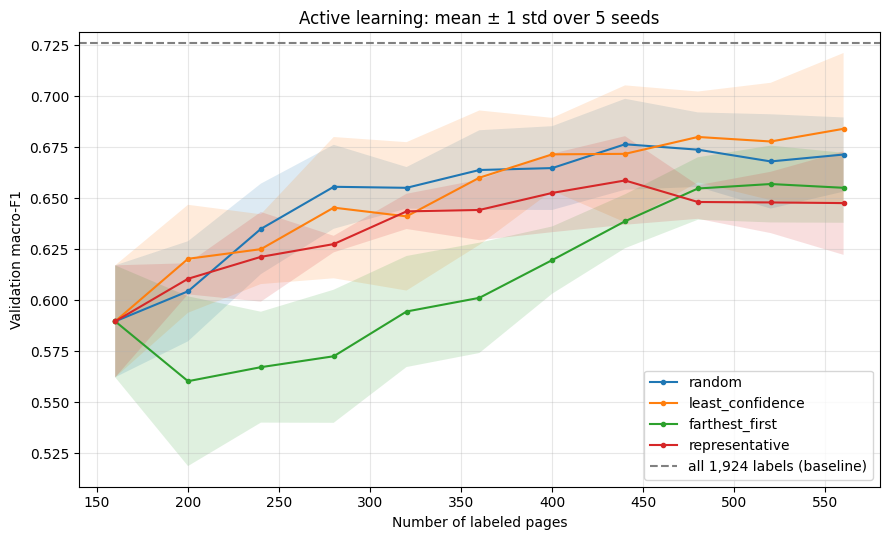

In [6]:
summary = (
    results.groupby(["strategy", "n_labeled"])["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5.5))
for strategy in STRATEGIES:
    s = summary[summary["strategy"] == strategy]
    ax.plot(s["n_labeled"], s["mean"], marker="o", markersize=3, label=strategy)
    ax.fill_between(s["n_labeled"], s["mean"] - s["std"], s["mean"] + s["std"], alpha=0.15)

ax.axhline(0.726, color="gray", linestyle="--", label="all 1,924 labels (baseline)")
ax.set_xlabel("Number of labeled pages")
ax.set_ylabel("Validation macro-F1")
ax.set_title("Active learning: mean ± 1 std over 5 seeds")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

In [7]:
# Mean macro-F1 at selected label budgets
budget_table = summary.pivot(index="n_labeled", columns="strategy", values="mean")[STRATEGIES]
display(budget_table.loc[[160, 240, 320, 400, 480, 560]].round(3))

# Per seed: difference to random after the full budget (positive = better than random)
final_by_seed = final.pivot(index="seed", columns="strategy", values="macro_f1")
diff_vs_random = final_by_seed[STRATEGIES[1:]].sub(final_by_seed["random"], axis=0)
display(diff_vs_random.round(3))
print("Seeds (out of 5) where the strategy beats random:", (diff_vs_random > 0).sum().to_dict())

strategy,random,least_confidence,farthest_first,representative
n_labeled,,,,
160,0.590,0.590,0.590,0.590
240,0.635,0.625,0.567,0.621
320,0.655,0.641,0.595,0.644
400,0.665,0.672,0.620,0.653
480,0.674,0.680,0.655,0.648
560,0.671,0.684,0.655,0.648


strategy,least_confidence,farthest_first,representative
seed,,,
42,-0.035,-0.040,-0.084
43,0.057,0.001,-0.042
44,0.005,-0.029,-0.008
45,0.040,-0.007,-0.008
46,-0.003,-0.006,0.024


Seeds (out of 5) where the strategy beats random: {'least_confidence': 3, 'farthest_first': 1, 'representative': 1}


### 5.2 Observations

- **Start:** with 160 labels the model reaches a mean macro-F1 of 0.591 (between seeds the initial value varies, e.g. 0.624 for seed 42).
- **Random sampling is strong early on.** Between 200 and 440 labels, random is the best or equal-best strategy (e.g. 400 labels: random 0.666, least confidence 0.657).
- **Least confidence is best only at the end.** It overtakes random at about 480 labels and finishes highest (0.682 vs 0.671 after 560 labels). It beats random in 4 of 5 seeds, but the differences are small (−0.003 to +0.029) and smaller than the variation between seeds (std ≈ 0.017).
- **Farthest-first first gets worse:** macro-F1 drops from 0.591 to 0.562 after the first batch, because the batch is filled with empty-OCR pages (see Section 3). It recovers slowly and finishes at 0.659, below random.
- **Representative sampling** follows random at first but falls behind from about 400 labels (0.651 at the end; better than random in only 2 of 5 seeds).
- **The bands overlap strongly**, so most differences between strategies are within the run-to-run variability.
- **No strategy reaches the full-data model:** after 560 labels (29% of the pool), the best mean is 0.682, compared with 0.726 when all 1,924 pages are labeled.

## 6. Discussion

**Initial set.** 20 pages per class (160, ≈8% of the pool) ensures every class is present and gives a usable first model (mean macro-F1 0.59), while leaving a large pool (1,764 pages) for acquisition. The initial value varies between seeds, which is one reason for repeating the experiment.

**Acquisition functions.**
- *Uncertainty (least confidence):* uses the model's predicted probabilities. Our baseline showed that wrong predictions have lower confidence, so this is a meaningful signal for our task. Limitation: taking the top 40 can give a redundant batch (16 forms in the first batch).
- *Diversity (farthest-first):* uses cosine distance between character n-gram TF-IDF vectors. Limitation: pages with empty or very short OCR have (near-)zero vectors and therefore look maximally different from everything, so the strategy selects them first, although a text model cannot learn from them.
- *Representativeness (relative):* compares average similarity to the pool with average similarity to the labeled set. Limitation: it is based on mean vectors, which is a coarse summary, and in our data it favoured short pages.

**Does active learning beat random sampling?** Only slightly, and only late: least confidence ends 0.011 above random and wins in 4 of 5 seeds, but the gain is smaller than the variability between seeds. Diversity and representative sampling are worse than random. With this model and data we therefore find **no clear label-efficiency gain**, i.e. a negative result.

**Does the advantage change with more labels?** Yes. Early on, random is better: uncertainty selects difficult and partly ambiguous pages (e.g. presentation, form), which does not help a weak model yet. Later, when the model is more stable, uncertainty becomes slightly better.

**Stability.** Standard deviations of 0.015–0.026 and overlapping bands mean that 5 seeds are not enough to show a reliable difference of ≈0.01.

**Limitations.**
- Small validation set (235 pages) and only 5 repetitions.
- One configuration only (batch size 40, budget 400, one model); results may differ with other settings.
- The simulated oracle assumes correct labels. Real annotators may disagree, especially on ambiguous classes such as presentation (hypothesis H2 from the baseline).
- The geometric strategies depend on the representation: OCR noise and empty pages distort the similarity measure.

**Relevance for our project.** Active learning is not clearly worth it in this setting: random sampling already performs well, and the gains of uncertainty sampling are small. The results suggest two improvements that connect to later parts of the course: (1) pages without OCR text should not be offered to annotators for the text model; they should rather go directly to human review or be handled with the page image (modality); (2) uncertainty sampling should be combined with a diversity component to avoid redundant batches (Lab 5: combined policies).

## 7. Conclusions

1. With 160 initial labels and 400 additional labels, **least-confidence sampling** gives the highest final macro-F1 (0.682 vs 0.671 for random), but the advantage is small, appears only late and is within the run-to-run variability.
2. **Farthest-first diversity** and **representative sampling** perform worse than random, mainly because they select pages with empty or very short OCR text.
3. Even after labeling 29% of the pool, all strategies remain below the model trained on all labels (0.726).
4. For a scanned-document workflow, **data quality (empty OCR) matters more than the acquisition strategy**: pages without usable text should be routed to a person or to an image-based model rather than used as training data for the text model.